In [6]:
import numpy as np, glob
from PIL import Image
def load(p): return np.array(Image.open(p).convert('RGB')).astype(float)

FF   = '/kaggle/input/datasets/aratisutar/phasea-run3'
IN_A = '/kaggle/input/notebooks/aratisutar/prior-swap-l5'
IN_B = '/kaggle/input/notebooks/aratisutar/level-2'
NM = {0:'faces', 2:'animal faces', 5:'landscapes'}

def comps(base, folder, truth, k=6):
    fs = sorted(glob.glob(f'{base}/{folder}/*.png'))[:k]
    if len(fs) < k: return None
    S = np.stack([load(f) for f in fs]); T = load(f'{base}/{truth}.png')
    sp = np.mean([np.abs(S[a]-S[b]).mean() for a in range(k) for b in range(a+1,k)])
    er = np.mean([np.abs(s-T).mean() for s in S])
    return sp, er, sp/er, S.mean(), T.mean()

def inet(lvl, i):
    for b in (IN_A, IN_B):
        r = comps(b, f'IN_L{lvl}_{i:05d}', f'truth_IN_L{lvl}_{i:05d}')
        if r: return r
    return None

print('=== SPREAD AND ERROR SEPARATELY ===\n')
print(f"{'level':<14s} {'prior':<9s} {'n':>2s} {'spread':>8s} {'error':>8s} {'ratio':>7s}")
for lvl in [0,2,5]:
    ff_s, in_s = [], []
    for i in range(10):
        a = comps(FF, f'P_L{lvl}_{i:05d}', f'truth_L{lvl}_{i:05d}')
        b = inet(lvl, i)
        if a and b: ff_s.append(a); in_s.append(b)
    A = np.array([x[:3] for x in ff_s]); B = np.array([x[:3] for x in in_s])
    print(f'{NM[lvl]:<14s} {"FFHQ":<9s} {len(A):2d} {A[:,0].mean():8.2f} '
          f'{A[:,1].mean():8.2f} {A[:,2].mean():7.3f}')
    print(f'{"":14s} {"ImageNet":<9s} {len(B):2d} {B[:,0].mean():8.2f} '
          f'{B[:,1].mean():8.2f} {B[:,2].mean():7.3f}')
    print(f'{"":14s} {"change":<9s} {"":2s} {B[:,0].mean()-A[:,0].mean():+8.2f} '
          f'{B[:,1].mean()-A[:,1].mean():+8.2f} {B[:,2].mean()-A[:,2].mean():+7.3f}\n')

print('\n=== BRIGHTNESS: SYSTEMATIC OR ONE IMAGE? ===\n')
print(f"{'level':<14s} {'img':>3s} {'truth':>8s} {'FFHQ':>8s} {'IN':>8s} "
      f"{'d_FF':>7s} {'d_IN':>7s}")
allff, allin = [], []
for lvl in [0,2,5]:
    for i in range(10):
        a = comps(FF, f'P_L{lvl}_{i:05d}', f'truth_L{lvl}_{i:05d}')
        b = inet(lvl, i)
        if not (a and b): continue
        allff.append(a[3]-a[4]); allin.append(b[3]-b[4])
        print(f'{NM[lvl]:<14s} {i:3d} {a[4]:8.1f} {a[3]:8.1f} {b[3]:8.1f} '
              f'{a[3]-a[4]:+7.1f} {b[3]-b[4]:+7.1f}')
    print()
print(f'mean offset  FFHQ {np.mean(allff):+6.2f}   ImageNet {np.mean(allin):+6.2f}')
print(f'sd           FFHQ {np.std(allff):6.2f}   ImageNet {np.std(allin):6.2f}')

=== SPREAD AND ERROR SEPARATELY ===

level          prior      n   spread    error   ratio
faces          FFHQ       5     9.62    11.02   0.881
               ImageNet   5     9.52    11.14   0.866
               change          -0.09    +0.11  -0.015

animal faces   FFHQ      10    12.85    16.84   0.774
               ImageNet  10    12.34    14.43   0.859
               change          -0.52    -2.41  +0.085

landscapes     FFHQ      10     8.31    15.76   0.607
               ImageNet  10     9.38    14.47   0.757
               change          +1.07    -1.29  +0.150


=== BRIGHTNESS: SYSTEMATIC OR ONE IMAGE? ===

level          img    truth     FFHQ       IN    d_FF    d_IN
faces            0    109.5    108.9    109.4    -0.6    -0.1
faces            1     77.5     76.9     77.7    -0.6    +0.2
faces            2    113.2    109.4    109.1    -3.8    -4.1
faces            3    118.0    119.7    118.3    +1.6    +0.3
faces            4    148.6    151.7    148.1    +3.1    -0.5



In [7]:
T8 = load(f'{FF}/truth_L5_00008.png')
print('fraction at 0  :', round((T8 == 0).mean(), 4))
print('fraction at 255:', round((T8 == 255).mean(), 4))
print('fraction < 10  :', round((T8 < 10).mean(), 4))
print('fraction > 245 :', round((T8 > 245).mean(), 4))
print()
for i in [0,1,2,3,4,5,6,7,9]:
    t = load(f'{FF}/truth_L5_{i:05d}.png')
    print(f'img {i}: <10 {(t<10).mean():.4f}  >245 {(t>245).mean():.4f}')

fraction at 0  : 0.0006
fraction at 255: 0.0
fraction < 10  : 0.0067
fraction > 245 : 0.0001

img 0: <10 0.0389  >245 0.0039
img 1: <10 0.0112  >245 0.0087
img 2: <10 0.0035  >245 0.0036
img 3: <10 0.0046  >245 0.0346
img 4: <10 0.0002  >245 0.0000
img 5: <10 0.0010  >245 0.0286
img 6: <10 0.3255  >245 0.0133
img 7: <10 0.0200  >245 0.0029
img 9: <10 0.0055  >245 0.0063


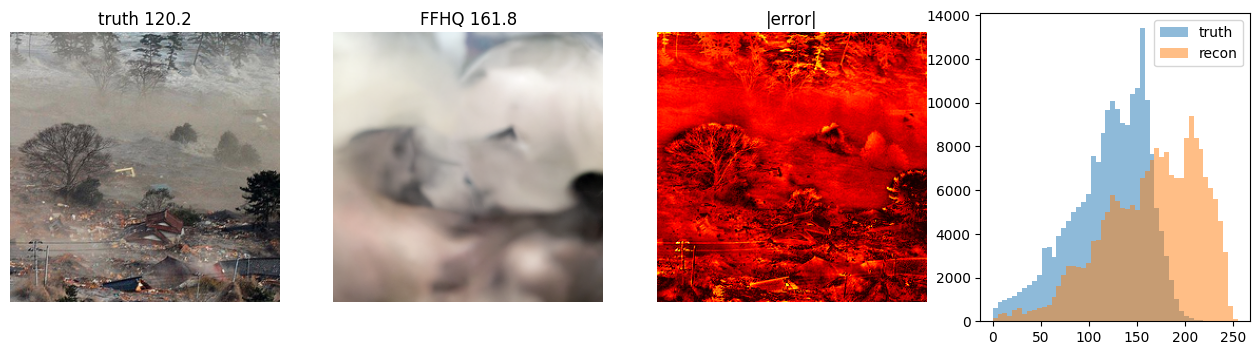

In [8]:
import matplotlib.pyplot as plt
T8 = load(f'{FF}/truth_L5_00008.png')
S8 = np.stack([load(f) for f in sorted(glob.glob(f'{FF}/P_L5_00008/*.png'))[:6]])
fig, ax = plt.subplots(1,4, figsize=(16,4))
ax[0].imshow(T8.astype('uint8')); ax[0].set_title('truth 120.2')
ax[1].imshow(S8[0].astype('uint8')); ax[1].set_title('FFHQ 161.8')
ax[2].imshow(np.abs(S8[0]-T8).mean(axis=2), cmap='hot'); ax[2].set_title('|error|')
ax[3].hist(T8.ravel(), bins=50, alpha=0.5, label='truth')
ax[3].hist(S8[0].ravel(), bins=50, alpha=0.5, label='recon'); ax[3].legend()
for a in ax[:3]: a.axis('off')
plt.show()

In [9]:
err = (S8.mean(axis=0) - T8).mean(axis=2)
print('mean signed error:', round(err.mean(),1))
print('by quadrant:')
for name, sl in [('top-left',(slice(0,128),slice(0,128))), ('top-right',(slice(0,128),slice(128,256))),
                 ('bot-left',(slice(128,256),slice(0,128))), ('bot-right',(slice(128,256),slice(128,256)))]:
    print(f'  {name:10s} {err[sl].mean():+7.1f}')
print('\nby truth brightness:')
t = T8.mean(axis=2)
for lo, hi in [(0,50),(50,100),(100,150),(150,200),(200,256)]:
    m = (t>=lo)&(t<hi)
    if m.sum(): print(f'  truth {lo:3d}-{hi:3d}: {m.mean()*100:5.1f}% of pixels, error {err[m].mean():+7.1f}')

mean signed error: 41.6
by quadrant:
  top-left     +52.6
  top-right    +53.7
  bot-left     +36.6
  bot-right    +23.5

by truth brightness:
  truth   0- 50:   6.4% of pixels, error   +29.7
  truth  50-100:  21.3% of pixels, error   +34.4
  truth 100-150:  44.9% of pixels, error   +41.6
  truth 150-200:  27.3% of pixels, error   +50.4
  truth 200-256:   0.2% of pixels, error   -25.2


In [10]:
import glob
print(glob.glob('/kaggle/input/**/P_L5_00008*', recursive=True))

['/kaggle/input/datasets/aratisutar/phasea-run3/P_L5_00008']


In [11]:
t = T8.mean(axis=2).ravel()
r = S8.mean(axis=0).mean(axis=2).ravel()
a, b = np.polyfit(t, r, 1)
pred = a*t + b
r2 = 1 - ((r-pred)**2).sum()/((r-r.mean())**2).sum()
print(f'recon = {a:.3f} * truth + {b:.1f}')
print(f'R^2 = {r2:.3f}')
print()
tt = T8.mean(axis=2)
print('truth brightness by quadrant:')
for nm, sl in [('top-left',(slice(0,128),slice(0,128))), ('top-right',(slice(0,128),slice(128,256))),
               ('bot-left',(slice(128,256),slice(0,128))), ('bot-right',(slice(128,256),slice(128,256)))]:
    print(f'  {nm:10s} truth {tt[sl].mean():6.1f}   predicted error {(a-1)*tt[sl].mean()+b:+6.1f}')
print()
print('same fit on a normal landscape (image 6):')
T6 = load(f'{FF}/truth_L5_00006.png')
S6 = np.stack([load(f) for f in sorted(glob.glob(f'{FF}/P_L5_00006/*.png'))[:6]])
a6, b6 = np.polyfit(T6.mean(axis=2).ravel(), S6.mean(axis=0).mean(axis=2).ravel(), 1)
print(f'  recon = {a6:.3f} * truth + {b6:.1f}')

recon = 1.145 * truth + 24.2
R^2 = 0.783

truth brightness by quadrant:
  top-left   truth  141.8   predicted error  +44.7
  top-right  truth  143.0   predicted error  +44.9
  bot-left   truth  111.4   predicted error  +40.3
  bot-right  truth   84.7   predicted error  +36.5

same fit on a normal landscape (image 6):
  recon = 0.969 * truth + 3.1


In [12]:
print(f"{'level':<14s} {'img':>3s} {'truth':>7s} {'slope':>7s} {'intercept':>10s} {'R2':>6s}")
rows = []
for lvl in [0,2,5]:
    for i in range(10):
        tp = f'{FF}/truth_L{lvl}_{i:05d}.png'
        fs = sorted(glob.glob(f'{FF}/P_L{lvl}_{i:05d}/*.png'))[:6]
        if len(fs) < 6: continue
        T = load(tp); S = np.stack([load(f) for f in fs]).mean(axis=0)
        t, r = T.mean(axis=2).ravel(), S.mean(axis=2).ravel()
        a, b = np.polyfit(t, r, 1)
        pred = a*t+b
        r2 = 1 - ((r-pred)**2).sum()/((r-r.mean())**2).sum()
        rows.append((lvl, i, T.mean(), a, b, r2))
        print(f'{NM[lvl]:<14s} {i:3d} {T.mean():7.1f} {a:7.3f} {b:10.1f} {r2:6.3f}')
rows = np.array([[r[2],r[3],r[4]] for r in rows])
print(f'\nslope: mean {rows[:,1].mean():.3f}  sd {rows[:,1].std():.3f}')
print(f'correlation slope vs truth brightness: {np.corrcoef(rows[:,0], rows[:,1])[0,1]:+.3f}')

level          img   truth   slope  intercept     R2
faces            0   109.5   0.943        5.6  0.959
faces            1    77.5   0.934        4.5  0.950
faces            2   113.2   0.993       -3.0  0.965
faces            3   118.0   0.983        3.6  0.978
faces            4   148.6   0.915       15.7  0.905
faces            5    92.5   0.997       -5.4  0.969
faces            6   168.2   1.011       -6.3  0.967
faces            7    67.7   0.926        5.2  0.932
faces            8    76.4   1.054        2.5  0.971
faces            9   154.8   0.971        3.6  0.966
animal faces     0   129.8   1.012        1.9  0.971
animal faces     1    85.5   0.986        8.2  0.923
animal faces     2   114.2   0.899       18.4  0.865
animal faces     3    91.7   0.975       -3.1  0.957
animal faces     4   129.2   0.967       -1.6  0.936
animal faces     5    74.7   0.940       16.5  0.829
animal faces     6   114.8   0.962        2.6  0.965
animal faces     7   134.8   0.848       25.7 

In [13]:
t = T8.mean(axis=2).ravel()
a, b = np.polyfit(t, S8.mean(axis=0).mean(axis=2).ravel(), 1)
S8c = (S8 - b) / a                       # undo the fitted transform
k = len(S8c)
sp_c = np.mean([np.abs(S8c[i]-S8c[j]).mean() for i in range(k) for j in range(i+1,k)])
er_c = np.mean([np.abs(s-T8).mean() for s in S8c])
sp_o = np.mean([np.abs(S8[i]-S8[j]).mean() for i in range(k) for j in range(i+1,k)])
er_o = np.mean([np.abs(s-T8).mean() for s in S8])
print(f'original  : spread {sp_o:6.2f}  error {er_o:6.2f}  ratio {sp_o/er_o:.3f}')
print(f'corrected : spread {sp_c:6.2f}  error {er_c:6.2f}  ratio {sp_c/er_c:.3f}')
print(f'other landscapes mean ratio: 0.648')

original  : spread  10.52  error  44.36  ratio 0.237
corrected : spread   9.19  error  16.86  ratio 0.545
other landscapes mean ratio: 0.648


In [14]:
def ratio_corrected(base, folder, truth, k=6):
    fs = sorted(glob.glob(f'{base}/{folder}/*.png'))[:k]
    if len(fs) < k: return None
    S = np.stack([load(f) for f in fs]); T = load(f'{base}/{truth}.png')
    a, b = np.polyfit(T.mean(axis=2).ravel(), S.mean(axis=0).mean(axis=2).ravel(), 1)
    Sc = (S - b) / a
    sp = np.mean([np.abs(Sc[i]-Sc[j]).mean() for i in range(k) for j in range(i+1,k)])
    er = np.mean([np.abs(s-T).mean() for s in Sc])
    return sp/er

print(f"{'level':<14s} {'img':>3s} {'FFHQ':>8s} {'IN':>8s} {'diff':>8s}")
from math import comb
for lvl in [0,2,5]:
    ds = []
    for i in range(10):
        ff = ratio_corrected(FF, f'P_L{lvl}_{i:05d}', f'truth_L{lvl}_{i:05d}')
        inn = None
        for b_ in (IN_A, IN_B):
            inn = ratio_corrected(b_, f'IN_L{lvl}_{i:05d}', f'truth_IN_L{lvl}_{i:05d}')
            if inn: break
        if ff and inn:
            ds.append(inn-ff)
            print(f'{NM[lvl]:<14s} {i:3d} {ff:8.3f} {inn:8.3f} {inn-ff:+8.3f}')
    n, pos = len(ds), int((np.array(ds)>0).sum())
    tail = sum(comb(n,x) for x in range(max(pos,n-pos), n+1))
    print(f'{"":14s} {"":3s} {"":8s} {"":8s} {np.mean(ds):+8.3f}'
          f'   {pos}/{n}  p={min(1.0,2*tail/2**n):.4f}\n')

level          img     FFHQ       IN     diff
faces            0    0.876    0.893   +0.017
faces            1    0.930    0.865   -0.065
faces            2    0.930    0.926   -0.004
faces            3    0.938    0.918   -0.020
faces            4    0.810    0.789   -0.021
                                       -0.019   1/5  p=0.3750

animal faces     0    0.898    0.914   +0.015
animal faces     1    0.732    0.830   +0.098
animal faces     2    0.709    0.880   +0.171
animal faces     3    0.811    0.866   +0.055
animal faces     4    0.787    0.796   +0.009
animal faces     5    0.783    0.842   +0.059
animal faces     6    0.858    0.950   +0.093
animal faces     7    1.001    1.006   +0.005
animal faces     8    0.743    0.888   +0.145
animal faces     9    0.875    0.917   +0.042
                                       +0.069   10/10  p=0.0020

landscapes       0    0.730    0.749   +0.019
landscapes       1    0.692    0.802   +0.110
landscapes       2    0.765    0.923   +0.15

In [15]:
!grep -rn "def clear_color\|def normalize_np\|normalize_np(\|clear_color(" /kaggle/input/datasets/aratisutar/dps-code/

/kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/guided_diffusion/gaussian_diffusion.py:205:                    plt.imsave(file_path, clear_color(img))
/kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/sample_condition.py:116:        plt.imsave(os.path.join(out_path, 'input', fname), clear_color(y_n))
/kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/sample_condition.py:117:        plt.imsave(os.path.join(out_path, 'label', fname), clear_color(ref_img))
/kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/sample_condition.py:118:        plt.imsave(os.path.join(out_path, 'recon', fname), clear_color(sample))
/kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/util/img_utils.py:42:    return normalize_np(x)
/kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/util/img_utils.py:45:def clear_color(x):
/kaggle/input/datasets/aratisutar/dp

In [16]:
!grep -n -A8 "def normalize_np" /kaggle/input/datasets/aratisutar/dps-code/diffusion-posterior-sampling-main/util/img_utils.py

52:def normalize_np(img):
53-    """ Normalize img in arbitrary range to [0, 1] """
54-    img -= np.min(img)
55-    img /= np.max(img)
56-    return img
57-
58-
59-def prepare_im(load_dir, image_size, device):
60-    ref_img = torch.from_numpy(normalize_np(plt.imread(load_dir)[:, :, :3].astype(np.float32))).to(device)


In [17]:
import numpy as np, glob
from PIL import Image
def load(p): return np.array(Image.open(p).convert('RGB')).astype(float)

FF = '/kaggle/input/datasets/aratisutar/phasea-run3'
T8 = load(f'{FF}/truth_L5_00008.png')
S8 = np.stack([load(f) for f in sorted(glob.glob(f'{FF}/P_L5_00008/*.png'))[:6]])

for nm, img in [('truth', T8), ('recon', S8[0])]:
    g = img.mean(axis=2)
    print(f'{nm:6s}  pixels < 5: {(g<5).sum():6d}   pixels < 20: {(g<20).sum():6d}   '
          f'pixels > 250: {(g>250).sum():6d}')

truth   pixels < 5:    138   pixels < 20:   1088   pixels > 250:      0
recon   pixels < 5:     37   pixels < 20:    339   pixels > 250:     20


In [18]:
import numpy as np, glob
from PIL import Image
from math import comb
def load(p): return np.array(Image.open(p).convert('RGB')).astype(float)

FF = '/kaggle/input/datasets/aratisutar/phasea-run3'
IN_SOURCES = [p for p in glob.glob('/kaggle/input/notebooks/*/*')
              if glob.glob(f'{p}/IN_L*')]
print('ImageNet sources:')
for p in IN_SOURCES:
    print(f'  {len(glob.glob(f"{p}/IN_L0_*")):2d} face folders   {p}')

def get(base, folder, truth, k=6, correct=False):
    fs = sorted(glob.glob(f'{base}/{folder}/*.png'))[:k]
    if len(fs) < k: return None
    S = np.stack([load(f) for f in fs]); T = load(f'{base}/{truth}.png')
    if correct:
        a, b = np.polyfit(T.mean(axis=2).ravel(), S.mean(axis=0).mean(axis=2).ravel(), 1)
        S = (S - b) / a
    sp = np.mean([np.abs(S[i]-S[j]).mean() for i in range(k) for j in range(i+1,k)])
    er = np.mean([np.abs(s-T).mean() for s in S])
    return sp/er

def inet(lvl, i, correct):
    for b in IN_SOURCES:
        r = get(b, f'IN_L{lvl}_{i:05d}', f'truth_IN_L{lvl}_{i:05d}', correct=correct)
        if r is not None: return r
    return None

def sign(d):
    n, pos = len(d), int((np.array(d)>0).sum())
    tail = sum(comb(n,x) for x in range(max(pos,n-pos), n+1))
    return pos, n, min(1.0, 2*tail/2**n)

NM = {0:'faces', 2:'animal faces', 5:'landscapes'}
for correct in [False, True]:
    print(f'\n=== {"CORRECTED" if correct else "RAW"} ===')
    for lvl in [0,2,5]:
        d = []
        for i in range(10):
            ff = get(FF, f'P_L{lvl}_{i:05d}', f'truth_L{lvl}_{i:05d}', correct=correct)
            inn = inet(lvl, i, correct)
            if ff is not None and inn is not None: d.append(inn-ff)
        pos, n, p = sign(d)
        print(f'  {NM[lvl]:<14s} n={n:2d}  mean {np.mean(d):+.3f}  improved {pos}/{n}  p = {p:.4f}')

ImageNet sources:
   0 face folders   /kaggle/input/notebooks/aratisutar/level-2
   5 face folders   /kaggle/input/notebooks/aratisutar/imagenet-faces-5to9
   5 face folders   /kaggle/input/notebooks/aratisutar/prior-swap-l5

=== RAW ===
  faces          n= 5  mean -0.015  improved 1/5  p = 0.3750
  animal faces   n=10  mean +0.085  improved 9/10  p = 0.0215
  landscapes     n=10  mean +0.150  improved 10/10  p = 0.0020

=== CORRECTED ===
  faces          n= 5  mean -0.019  improved 1/5  p = 0.3750
  animal faces   n=10  mean +0.069  improved 10/10  p = 0.0020
  landscapes     n=10  mean +0.101  improved 10/10  p = 0.0020


In [19]:
K_BY_LEVEL = {0: 5, 2: 6, 5: 6}   # faces use 5: the faces run hit the 12-hour limit

for correct in [False, True]:
    print(f'\n=== {"CORRECTED" if correct else "RAW"} ===')
    for lvl in [0,2,5]:
        k = K_BY_LEVEL[lvl]
        d = []
        for i in range(10):
            ff  = get(FF, f'P_L{lvl}_{i:05d}', f'truth_L{lvl}_{i:05d}', k=k, correct=correct)
            inn = None
            for b in IN_SOURCES:
                inn = get(b, f'IN_L{lvl}_{i:05d}', f'truth_IN_L{lvl}_{i:05d}', k=k, correct=correct)
                if inn is not None: break
            if ff is not None and inn is not None: d.append(inn-ff)
        pos, n, p = sign(d)
        print(f'  {NM[lvl]:<14s} k={k}  n={n:2d}  mean {np.mean(d):+.3f}  improved {pos}/{n}  p = {p:.4f}')


=== RAW ===
  faces          k=5  n=10  mean +0.003  improved 5/10  p = 1.0000
  animal faces   k=6  n=10  mean +0.085  improved 9/10  p = 0.0215
  landscapes     k=6  n=10  mean +0.150  improved 10/10  p = 0.0020

=== CORRECTED ===
  faces          k=5  n=10  mean -0.006  improved 5/10  p = 1.0000
  animal faces   k=6  n=10  mean +0.069  improved 10/10  p = 0.0020
  landscapes     k=6  n=10  mean +0.101  improved 10/10  p = 0.0020


In [20]:
def se(base, folder, truth, k=5):
    fs = sorted(glob.glob(f'{base}/{folder}/*.png'))[:k]
    if len(fs) < k: return None
    S = np.stack([load(f) for f in fs]); T = load(f'{base}/{truth}.png')
    sp = np.mean([np.abs(S[i]-S[j]).mean() for i in range(k) for j in range(i+1,k)])
    er = np.mean([np.abs(s-T).mean() for s in S])
    return sp, er

ff, inn = [], []
for i in range(10):
    a = se(FF, f'P_L0_{i:05d}', f'truth_L0_{i:05d}')
    b = None
    for src in IN_SOURCES:
        b = se(src, f'IN_L0_{i:05d}', f'truth_IN_L0_{i:05d}')
        if b: break
    if a and b: ff.append(a); inn.append(b)
ff, inn = np.array(ff), np.array(inn)
print(f'faces n={len(ff)}: spread {ff[:,0].mean():.2f} to {inn[:,0].mean():.2f} '
      f'({inn[:,0].mean()-ff[:,0].mean():+.2f}), '
      f'error {ff[:,1].mean():.2f} to {inn[:,1].mean():.2f} '
      f'({inn[:,1].mean()-ff[:,1].mean():+.2f})')

faces n=10: spread 9.81 to 10.04 (+0.23), error 11.11 to 11.34 (+0.23)
